# EDA


## Loading data and introduction

Welcome to my Exploratory Data Analysis, I hope you will find my work satisfactory. 

Firstly, I need you to know that this analysis is primarly written from the machine learning perspective. I still want to follow some general principles for a good EDA just for the sake of it, but the main goal for me was to find out what is the structure of data, how to fill out missing values efficiently and which ML model should I choose. I want to make it clear, because there are some missing parts of statistical analysis that would typicaly make it to the analysis (like for example skewness and curtosis). As scary as it may sound, this won't be very problematic since I acknowledge various details, but decide not to mention them up-close if they are not important for my task. That's also the reason why my work has rather unorthodox structure: null values analysis is at the end of 'one dimentional analysis' part, because I wanted to use knowledge about correlations and data structure before i mindlessly fill out nulls with means or zeros.

Secondly, I assume, that the reader is familiar with PDF file which was sent via e-mail, that encloses some basic information about the dataset and the recruitment task. If it's not the case, there's the description of columns from the said file:
- DepartureDate – date of departure 
- DepartureYear – year of departure 
- DepartureMonth – month of departure 
- DepartureDay – day of departure 
- FlightNumber – fight number 
- DepartureAirport – departure airport code 
- ArrivalAirport – arrival airport code  
- Route - route 
- ActualFlightTime – flight time 
- ActualTotalFuel – burnt fuel 
- ActualTOW - take-off weight (kg) 
- FlownPassengers – flown pax 
- BagsCount – flown bags 
- FlightBagsWeight – flown bags weight

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
import os
from plotly.subplots import make_subplots
import missingno as msno
import numpy as np
from utils.coordinates_imputer import longitude, latitude, coordinate_imputer

In [3]:
path_to_training_file = os.path.join('datasets', 'training.csv')
path_to_validation_file = os.path.join('datasets', 'validation.csv')


df_training = pd.read_csv(path_to_training_file, sep='\t')
df_validation = pd.read_csv(path_to_validation_file, sep='\t')


In [4]:
columns_to_convert = ['ActualTOW','FLownPassengers','BagsCount','FlightBagsWeight']
for i in columns_to_convert:
    df_training[f'{i}']=pd.to_numeric(df_training[f'{i}'], errors='coerce')
val_columns_to_convert = ['FLownPassengers','BagsCount','FlightBagsWeight']
for i in val_columns_to_convert:
    df_validation[f'{i}']=pd.to_numeric(df_validation[f'{i}'], errors='coerce')

In [5]:

df = pd.concat([df_training,df_validation], axis=0)

In [6]:
df.head()

,DepartureDate,DepartureYear,DepartureMonth,DepartureDay,FlightNumber,DepartureAirport,ArrivalAirport,Route,ActualFlightTime,ActualTotalFuel,ActualTOW,FLownPassengers,BagsCount,FlightBagsWeight
0,01/10/2016,2016,10,1,1145,MAN,SXF,MAN-SXF,91,3660,64016.0,175.0,61.0,440.0
1,01/10/2016,2016,10,1,1160,CTA,FCO,CTA-FCO,68,3280,66138.0,182.0,27.0,350.0
2,01/10/2016,2016,10,1,1183,LGW,SNN,LGW-SNN,64,2720,58447.0,127.0,NaN,NaN
3,01/10/2016,2016,10,1,1220,ATH,CHQ,ATH-CHQ,35,1682,60587.0,163.0,12.0,150.0
4,01/10/2016,2016,10,1,1225,CHQ,ATH,CHQ-ATH,34,1877,63090.0,178.0,37.0,490.0


In [7]:
print(df_training.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29731 entries, 0 to 29730
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   DepartureDate     29731 non-null  object 
 1   DepartureYear     29731 non-null  int64  
 2   DepartureMonth    29731 non-null  int64  
 3   DepartureDay      29731 non-null  int64  
 4   FlightNumber      29731 non-null  int64  
 5   DepartureAirport  29731 non-null  object 
 6   ArrivalAirport    29731 non-null  object 
 7   Route             29731 non-null  object 
 8   ActualFlightTime  29731 non-null  int64  
 9   ActualTotalFuel   29731 non-null  int64  
 10  ActualTOW         29298 non-null  float64
 11  FLownPassengers   29636 non-null  float64
 12  BagsCount         27447 non-null  float64
 13  FlightBagsWeight  27253 non-null  float64
dtypes: float64(4), int64(6), object(4)
memory usage: 3.2+ MB
None


In [8]:
print(df_validation.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1878 entries, 0 to 1877
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   DepartureDate     1878 non-null   object 
 1   DepartureYear     1878 non-null   int64  
 2   DepartureMonth    1878 non-null   int64  
 3   DepartureDay      1878 non-null   int64  
 4   FlightNumber      1878 non-null   int64  
 5   DepartureAirport  1878 non-null   object 
 6   ArrivalAirport    1878 non-null   object 
 7   Route             1878 non-null   object 
 8   ActualFlightTime  1878 non-null   int64  
 9   ActualTotalFuel   1878 non-null   int64  
 10  FLownPassengers   1869 non-null   float64
 11  BagsCount         1710 non-null   float64
 12  FlightBagsWeight  1697 non-null   float64
dtypes: float64(3), int64(6), object(4)
memory usage: 190.9+ KB
None


There are some null values in both training and validation datasets. Maybe the best method for filling out the missing values will be discovered later in the analysis. Let's take a look at the columns with 'object' data type:

## Categorical analysis

In [9]:
print(df_training['DepartureDate'].unique())
date_train = go.Figure()
date_train.add_trace(
                go.Histogram(x=df_training['DepartureDate']
                     )
                        )
date_train.update_layout(title='Distribution of departure dates')


['01/10/2016' '02/10/2016' '03/10/2016' '04/10/2016' '05/10/2016'
 '06/10/2016' '07/10/2016' '08/10/2016' '09/10/2016' '10/10/2016'
 '11/10/2016' '12/10/2016' '13/10/2016' '14/10/2016' '15/10/2016']


In [10]:
print(df_validation['DepartureDate'].unique())

['01/11/2016']


Now, there's the first obstacle which is an outlying date of '01/11/2016'. In the provided training dataset all the entries come from 01/10/2016-15/10/2016 period. It might cause some problems later, when the data will be used to train a machine learning model. Especially because there is no variation in the validation dataset when it comes to this specific column. 

On the other side, the distribution of dates is fairly uniform, which is a good sign in this case.

In [11]:
print(f'Amount of unique departure airports in training: {len(df_training['DepartureAirport'].unique())}, amount of unique values in validation: {len(df_validation['DepartureAirport'].unique())}')
print(f'5 most popular values {df['DepartureAirport'].value_counts().head(5)}')
print(f'5 least popular values {df['DepartureAirport'].value_counts().tail(5)}')
for i in df_validation['DepartureAirport'].values:
    if i not in df_training['DepartureAirport'].values:
        print(f"{i} not present in training set")

Amount of unique departure airports in training: 191, amount of unique values in validation: 170
5 most popular values DepartureAirport
STN    2740
DUB    1734
BGY    1227
BCN     944
CRL     816
Name: count, dtype: int64
5 least popular values DepartureAirport
OSL    4
CWL    2
LUX    2
SZY    1
VDA    1
Name: count, dtype: int64
OSL not present in training set
SZY not present in training set
LUX not present in training set
OSL not present in training set
OSL not present in training set
OSL not present in training set
LUX not present in training set
VDA not present in training set


It appears that despite being more rich in possible airport values, there are some locations that appear only in the validation dataset. Let's see if this problem is present in other columns. There is also a lot of variance in popularity of different airports which is problematic from the machine learning point of view, because the model won't have much samples for training.

In [12]:
print(f'Amount of unique arrival airports in training: {len(df_training['ArrivalAirport'].unique())}, amount of unique values in validation: {len(df_validation['ArrivalAirport'].unique())}')
print(f'5 most popular values {df['ArrivalAirport'].value_counts().head(5)}')
print(f'5 least popular values {df['ArrivalAirport'].value_counts().tail(5)}')
for i in df_validation['ArrivalAirport'].values:
    if i not in df_training['ArrivalAirport'].values:
        print(f"{i} not present in training set")

Amount of unique arrival airports in training: 190, amount of unique values in validation: 170
5 most popular values ArrivalAirport
STN    2741
DUB    1738
BGY    1231
BCN     943
CRL     816
Name: count, dtype: int64
5 least popular values ArrivalAirport
OSL    4
CWL    2
LUX    2
SZY    1
VDA    1
Name: count, dtype: int64
OSL not present in training set
SZY not present in training set
LUX not present in training set
OSL not present in training set
OSL not present in training set
OSL not present in training set
LUX not present in training set
VDA not present in training set


The same problem happens with arrival airports. Now, let's take a look how it affects the "Route" column, which is a combination of previous columns.

In [13]:
print(f'Amount of unique routes in training: {len(df_training['Route'].unique())}, amount of unique values in validation: {len(df_validation['Route'].unique())}')
print(f'5 most popular values {df['Route'].value_counts().head(5)}')
print(f'5 least popular values {df['Route'].value_counts().tail(5)}')

route_count=0
for i in df_validation['Route'].values:
    if i not in df_training['Route'].values:
        route_count += 1
print (f"Number of routes from validation not present in training set: {route_count}")

Amount of unique routes in training: 2667, amount of unique values in validation: 1383
5 most popular values Route
DUB-STN    129
STN-DUB    128
DUB-LGW    113
LGW-DUB    113
SKG-ATH    113
Name: count, dtype: int64
5 least popular values Route
HHN-FCO    1
PIS-PMI    1
PUY-ZAD    1
FCO-NYO    1
ALC-LGW    1
Name: count, dtype: int64
Number of routes from validation not present in training set: 122


Well, in this case it is more efficient to change string values to numeric (longitude, latitude). However, it is still to be decided how important is the location to the take-off weight.

In [14]:
df = coordinate_imputer(df, 'ArrivalAirport', latitude, longitude)
df = coordinate_imputer(df, 'DepartureAirport', latitude, longitude)

In [ ]:
fig = px.density_map(
    df,
    lat="ArrivalAirportLatitude",
    lon="ArrivalAirportLongitude",
    radius=10,
    center=dict(lat=0, lon=0),
    zoom=0,
    title='Arrival Airports interactive heatmap'
    #mapbox_style="open-street-map"
)
fig.show()

In [21]:
fig = px.density_map(
    df,
    lat="DepartureAirportLatitude",
    lon="DepartureAirportLongitude",
    radius=10,
    center=dict(lat=0, lon=0),
    zoom=0,
    title='Arrival Airports interactive heatmap',
    #animation_frame='ActualTOW'
    #mapbox_style="open-street-map"
)
fig.show()

Those maps are here just to visualize possible disproportions between all of the  airports, interestingly we have an outlying value of 'Seattle'  in the training set, which should be deleted in case when using ML model, because all of the flights take place in Europe and the example from USA might hurt the performance in the long run.

## Numerical analysis

In [ ]:
df_training.describe()

,DepartureYear,DepartureMonth,DepartureDay,FlightNumber,ActualFlightTime,ActualTotalFuel,ActualTOW,FLownPassengers,BagsCount,FlightBagsWeight
count,29731.0,29731.0,29731.000000,29731.000000,29731.000000,29731.000000,29298.000000,29636.000000,27447.000000,27253.000000
mean,2016.0,10.0,7.987723,4814.133934,110.069221,4782.483536,65031.246638,167.268626,45.417022,573.618464
std,0.0,0.0,4.313351,3062.612334,52.457470,2069.865460,3339.385728,20.177527,32.797217,376.524581
min,2016.0,10.0,1.000000,1.000000,2.000000,600.000000,42991.000000,4.000000,1.000000,3.000000
25%,2016.0,10.0,4.000000,2087.000000,73.000000,3210.000000,63127.000000,163.000000,23.000000,300.000000
50%,2016.0,10.0,8.000000,4765.000000,105.000000,4530.000000,65122.000000,173.000000,39.000000,490.000000
75%,2016.0,10.0,12.000000,7496.000000,140.000000,6010.000000,67154.000000,179.000000,62.000000,780.000000
max,2016.0,10.0,15.000000,9998.000000,1504.000000,17890.000000,74283.000000,189.000000,1180.000000,10530.000000


In [ ]:
df_validation.describe()

,DepartureYear,DepartureMonth,DepartureDay,FlightNumber,ActualFlightTime,ActualTotalFuel,FLownPassengers,BagsCount,FlightBagsWeight
count,1878.0,1878.0,1878.0,1878.000000,1878.000000,1878.000000,1869.000000,1710.000000,1697.000000
mean,2016.0,11.0,1.0,4673.227370,110.446219,4709.011715,166.103264,36.250292,446.149087
std,0.0,0.0,0.0,3069.845977,51.150847,2071.596772,26.391906,23.799249,275.057285
min,2016.0,11.0,1.0,11.000000,7.000000,1100.000000,6.000000,2.000000,20.000000
25%,2016.0,11.0,1.0,1995.250000,72.000000,3200.000000,163.000000,19.000000,250.000000
50%,2016.0,11.0,1.0,4566.500000,104.000000,4420.500000,174.000000,31.000000,390.000000
75%,2016.0,11.0,1.0,7452.750000,140.000000,5895.500000,180.000000,47.000000,590.000000
max,2016.0,11.0,1.0,9995.000000,318.000000,13040.000000,189.000000,260.000000,1700.000000


I will skip analysing the dates, because I already gave them some attention earlier in the categorical analysis and there is not much more to conclude from the table above.

Columns differ in their magnitude and concentrations. It will be very beneficial to use some sort of normalization and scaling later. Let's look at the columns in detail:

Flight number -  a value used only for identification, but it might provide some important insights, depending on the priciples used when determining the number. When researching the rules used by Ryanair I've found out, that the number of the flight is determined by some algorithm, without strict rules. Maybe some form of clustering will ne useful. 

Actual flight time - there's at least one outlying value which dominates the max value in the training dataset (note that the quantiles are almost the same) 

Actual total fuel - it is very natrual, that the outlying value of flight time also creates an outlying value in 'fuel' column (in this case the quantiles here are also very similar) 

Flight bags weight and bags count - same case as described above - outlying values in training set, similar distribution aside from that,

The remaining column 'Flown passengers' doesn't look problematic, especially because quantiles, variation, minimal and maximal values are similar enough for both datasets.

Now, let's take a look at the histograms of the remaining columns:

In [ ]:
barchart_general_training = make_subplots(
    rows=2, cols=3,
    subplot_titles=('ActualFlightTime', 'ActualTotalFuel','FlownPassengers', 
                    'BagsCount', 'FlightBagsWeight', 'ActualTOW')
)

barchart_general_training.add_trace(go.Histogram(
    x=df['ActualFlightTime'],
    name='ActualFlightTime',
)
    , row=1, col=1)

barchart_general_training.add_trace(go.Histogram(
    x=df['ActualTotalFuel'],
    name='ActualTotalFuel',
)
    , row=1, col=2)

barchart_general_training.add_trace(go.Histogram(
    x=df['FLownPassengers'],
    name='FLownPassengers',
)
    , row=1, col=3)

barchart_general_training.add_trace(go.Histogram(
    x=df['BagsCount'],
    name='BagsCount',
)
    , row=2, col=1)

barchart_general_training.add_trace(go.Histogram(
    x=df['FlightBagsWeight'],
    name='FlightBagsWeight',
)
    , row=2, col=2)

barchart_general_training.add_trace(go.Histogram(
    x=df['ActualTOW'],
    name='ActualTOW',
)
    , row=2, col=3)


It looks like different variations of exponential distribution are the most dominant among the columns in the dataset:
- Actual flight time - it has a bit of asymmetry on the right side, there's also a visible bump in the 200-250 range,
- Flown passengers - a typical example of reversed exponential distribution, looks very clean,
- Bags Count - it is a very steep and condensed distribution, but still folowing the pattern,
- Flight bags weight - very basic exponential distribution, with some skewness, but there's not much to see.

The remaining two histograms:
- Actual TOW - gaussian distribution - this one is pretty noisy around the mean, also there is no tail, which is unexpected from Gaussian distribution, but expected for a plane weight,
- Actual total fuel - looks a bit like a lognorm distribution with a fair bit of asymmetry and noise, this however can be justified, because data connected to fuel usage usually has similar distributions. 


<Axes: >

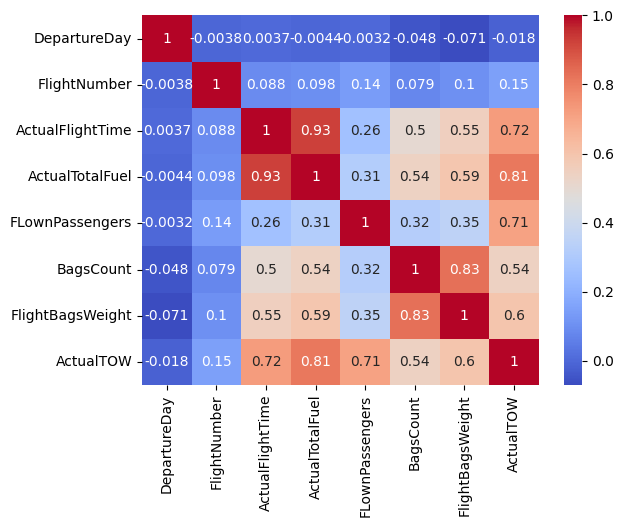

In [ ]:
sns.heatmap(df_training[['DepartureDay', 'FlightNumber', 'ActualFlightTime', 'ActualTotalFuel', 'FLownPassengers', 'BagsCount', 'FlightBagsWeight', 'ActualTOW']].corr(), annot=True, cmap='coolwarm')

The strongest of the correlations is obviously the one between burnt fuel and flight time, other than that, there are bags count and bags weight, actualTOW and total fuel burnt and flight time and actual TOW. Those dependencies are not too hard to understand, everything on board has impact on the plane weight, and the longer the route, the merer things on board. This explaination is of course oversimplified, but in my opinion good enough. The corr() method only describes linear relations between columns and high score is more important from the perspective of dimension reduction rather than finding subtle, hidden dependencies. 

I will come back to this matrix during the wisualization of dependencies part.

## Null values analysis

In [ ]:
print('Null values for training dataset:')
print(df_training.isnull().sum())


Null values for training dataset:
DepartureDate          0
DepartureYear          0
DepartureMonth         0
DepartureDay           0
FlightNumber           0
DepartureAirport       0
ArrivalAirport         0
Route                  0
ActualFlightTime       0
ActualTotalFuel        0
ActualTOW            433
FLownPassengers       95
BagsCount           2284
FlightBagsWeight    2478
dtype: int64


In [ ]:
print('Null values for validation dataset:')
df_validation.isnull().sum()

Null values for validation dataset:


DepartureDate         0
DepartureYear         0
DepartureMonth        0
DepartureDay          0
FlightNumber          0
DepartureAirport      0
ArrivalAirport        0
Route                 0
ActualFlightTime      0
ActualTotalFuel       0
FLownPassengers       9
BagsCount           168
FlightBagsWeight    181
dtype: int64

Looks like there are only four columns that contain null values. However, one of them is 'ActualTOW' column which is the value the model has to predict. There's a problem with that, because filling out the nulls syntheticaly may become harmful to the model because of the possible data structure violation and inbreeding, which is why I won't be doing so.

<Axes: >

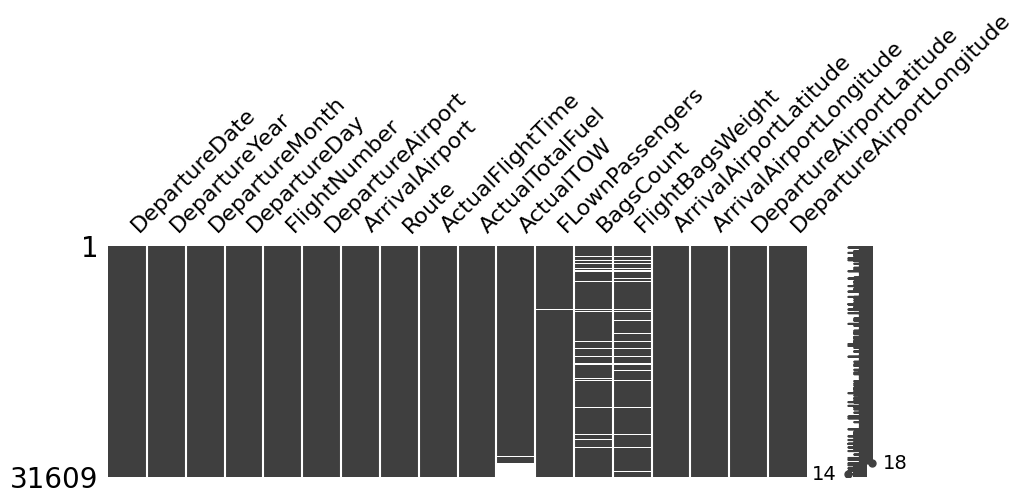

In [ ]:
msno.matrix(df, figsize=(10,3))


First thing that is very visible is the white rectangle in the 'Actual TOW' column, it is present, because I'm using both datasets combined and of course the validation dataset doesn't contain this column at all, I left it here to have a nice indicator where's the line separating both sets. 

There is some variation in the thickness of the lines, but so it is in their position, there are however, some visible clusters. We'll need to find out in detail how those thick lines and condensity in some regions work.

It is visible, that "Bags count" and "Bags weight" are correlated even in the field of unknown values. There are some exceptions to that rule, which means, that sometimes we know someting about one column without knowing what's in the other one.

<Axes: >

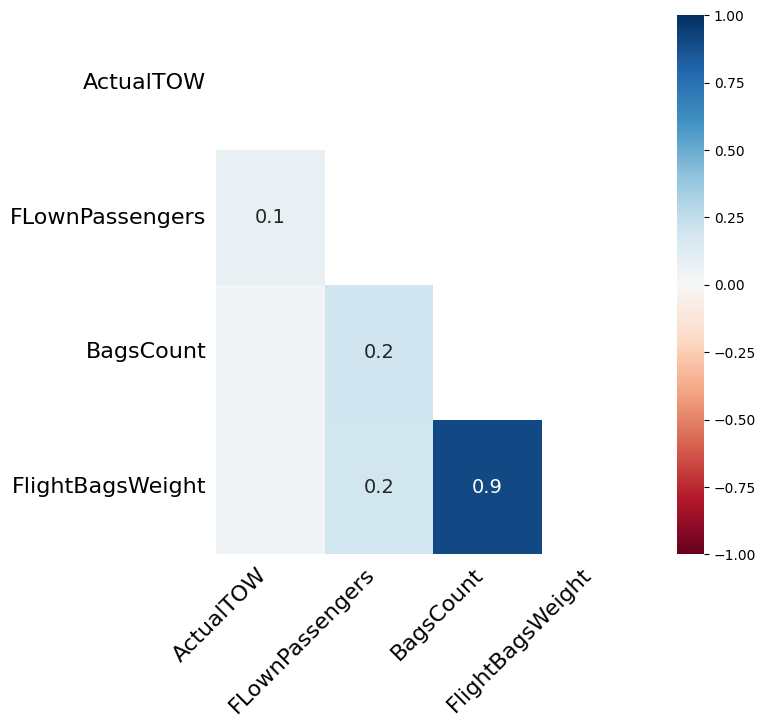

In [ ]:
msno.heatmap(df, figsize=(7,7))

This heatmap shows correlations behind missing values and apart from confirming my previous conclusion, it also says, that some missing values have a bit weaker correlations to them, that perhaps should not be ignored.

We of course want to know what accounts for the lack of values. There are few options and I'll start from the quick look at the numeric side of the dataset when divided into two parts; one, that has only non-null values in the 'BagsCount' column and one with null values. 

In [ ]:
df_no_null_bags = df[df['BagsCount'].notna()]
df_no_null_weights = df[df['FlightBagsWeight'].notna()]
df_no_null_bags.describe()


,DepartureYear,DepartureMonth,DepartureDay,FlightNumber,ActualFlightTime,ActualTotalFuel,ActualTOW,FLownPassengers,BagsCount,FlightBagsWeight,ArrivalAirportLatitude,ArrivalAirportLongitude,DepartureAirportLatitude,DepartureAirportLongitude
count,29157.0,29157.000000,29157.00000,29157.000000,29157.000000,29157.000000,27101.000000,29157.000000,29157.000000,28831.000000,29157.000000,29157.000000,29157.000000,29157.000000
mean,2016.0,10.058648,7.57746,4875.506534,110.100250,4785.885928,65087.324970,167.330384,44.879411,567.668482,46.230769,4.941863,46.224482,4.787391
std,0.0,0.234969,4.49742,3053.967473,51.031828,2057.009318,3242.874772,20.299884,32.410023,371.953076,6.886813,9.643285,6.887826,9.559576
min,2016.0,10.000000,1.00000,11.000000,2.000000,720.000000,49322.000000,6.000000,1.000000,6.000000,27.931900,-25.697900,27.931900,-25.697900
25%,2016.0,10.000000,4.00000,2137.000000,73.000000,3230.000000,63163.000000,163.000000,23.000000,300.000000,40.519700,-2.275000,40.519700,-2.275000
50%,2016.0,10.000000,8.00000,4852.000000,106.000000,4535.000000,65158.000000,173.000000,38.000000,480.000000,45.673900,2.738800,45.673900,2.738800
75%,2016.0,10.000000,12.00000,7592.000000,140.000000,6009.000000,67172.000000,179.000000,61.000000,780.000000,51.885000,12.238900,51.885000,12.238900
max,2016.0,11.000000,15.00000,9998.000000,1440.000000,14090.000000,74283.000000,189.000000,1180.000000,10530.000000,61.414100,34.935800,61.414100,34.935800


In [ ]:
df[df['BagsCount'].isnull()].describe()

,DepartureYear,DepartureMonth,DepartureDay,FlightNumber,ActualFlightTime,ActualTotalFuel,ActualTOW,FLownPassengers,BagsCount,FlightBagsWeight,ArrivalAirportLatitude,ArrivalAirportLongitude,DepartureAirportLatitude,DepartureAirportLongitude
count,2452.0,2452.000000,2452.000000,2452.000000,2452.000000,2452.000000,2197.000000,2348.000000,0.0,119.000000,2452.000000,2452.000000,2452.000000,2452.000000
mean,2016.0,10.068515,7.514274,3976.424551,109.988989,4685.752855,64339.494766,165.574106,NaN,197.386555,47.257650,3.601143,47.309672,5.239771
std,0.0,0.252680,4.500170,3051.381488,66.357053,2217.114916,4298.666255,23.960485,NaN,331.334209,6.922366,9.846769,6.875386,11.980195
min,2016.0,10.000000,1.000000,1.000000,12.000000,600.000000,42991.000000,4.000000,NaN,3.000000,27.931900,-25.697900,27.931900,-122.309400
25%,2016.0,10.000000,3.000000,1271.750000,67.000000,2920.000000,62583.000000,161.000000,NaN,26.000000,41.248100,-3.566800,41.800075,-3.372500
50%,2016.0,10.000000,7.000000,3018.000000,102.000000,4395.000000,64741.000000,173.000000,NaN,39.000000,50.714600,0.235000,50.865900,4.416400
75%,2016.0,10.000000,11.000000,6874.750000,138.000000,5940.250000,66845.000000,179.000000,NaN,243.000000,52.380000,11.288700,52.453900,12.656000
max,2016.0,11.000000,15.000000,9993.000000,1504.000000,17890.000000,74283.000000,189.000000,NaN,1677.000000,60.193900,32.485800,60.193900,33.624900


When it comes to the numeric side of non-null and null 'BagsCount' parts of the dataset the only difference in distributions is the 'flight bags weight'. This is our most important correlation both from the numeric and null values points of view. Let's take a look at the histogram beow:

In [ ]:
bags_count_weight_comparsion = go.Figure()

bags_count_weight_comparsion.add_trace(go.Histogram(
    x=df[df['BagsCount'].isnull()]['FlightBagsWeight'],
    name='null values'
))

bags_count_weight_comparsion.add_trace(go.Histogram(
    x=df_no_null_bags['FlightBagsWeight'],
    name='non-null values',
        opacity=0.3
))

bags_count_weight_comparsion.update_layout(title='FlightBagsWeight histograms for different "bags count" scenarios:')

In [ ]:
bags_count_weight_comparsion_v2 = go.Figure()

bags_count_weight_comparsion_v2.add_trace(go.Histogram(
    x=df[df['FlightBagsWeight'].isnull()]['BagsCount'],
    name='null values'
))

bags_count_weight_comparsion_v2.add_trace(go.Histogram(
    x=df_no_null_weights['BagsCount'],
    name='non-null values',
        opacity=0.3
))

bags_count_weight_comparsion_v2.update_layout(title='Bags count histograms for different "FlightBagsWeight" scenarios:')

Well, the sudden spike for the null values in the first histogram explains the thickness of lines in the null values matrix. We see, that when we have information about flight bags weight without having information about bags count, it usually occurs for low-weight cases. 

There is no such pattern in the reverse case.

Now, let's test a hypothesis: 
We want to check if those null values are in reality zeros, we might have an idea like this because the minimal value is one bag on the deck. If there are few flown passengers for null columns, it might be true. 

In [ ]:
null_bags_comparsion = go.Figure()

null_bags_comparsion.add_trace(go.Box(
    x=df[df['BagsCount'].isnull()]['FLownPassengers'],
    name='null values'
))

null_bags_comparsion.add_trace(go.Box(
    x=df_no_null_bags['FLownPassengers'],
    name='non-null values'
))

null_bags_comparsion.update_layout(title='Flown passengers boxplots for different "bags count" scenarios:')

In [ ]:
null_bags_weight_comparsion = go.Figure()
df_no_null_bag_weight = df[df['FlightBagsWeight'].notna()]

null_bags_weight_comparsion.add_trace(go.Box(
    x=df[df['FlightBagsWeight'].isnull()]['FLownPassengers'],
    name='null values'
))

null_bags_weight_comparsion.add_trace(go.Box(
    x=df_no_null_bags['FLownPassengers'],
    name='non-null values'
))

null_bags_weight_comparsion.update_layout(title='Flown passengers boxplots for different "flight bags weight" scenarios:')

Well, boxplots look very alike, even the outliers seem to be distributed similarly. Let's not give up yet, there might be some sort of a correlation between flown passengers and bags count or bags weight that can provide some helpful insights.

In [ ]:
airports_list = np.concatenate((df['ArrivalAirport'].unique(), df['DepartureAirport'].unique())).tolist()
keys_list = (longitude.keys())

In [ ]:
for i in airports_list:
    if i in keys_list:
        pass
    else:
        print(i)